In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../DATA/water_potability.csv')

In [3]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


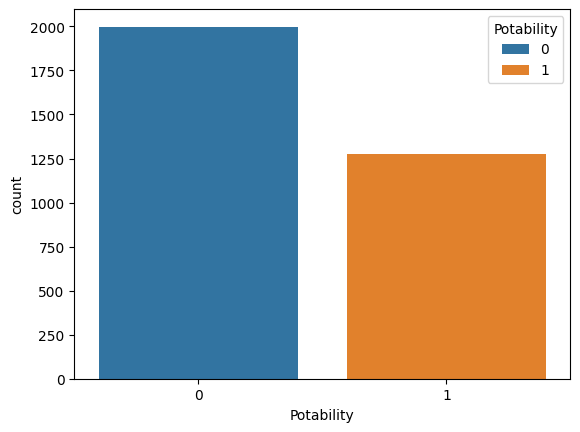

In [5]:
sns.countplot(data=df, x='Potability', hue='Potability');

In [6]:
df['Potability'].value_counts()

Potability
0    1998
1    1278
Name: count, dtype: int64

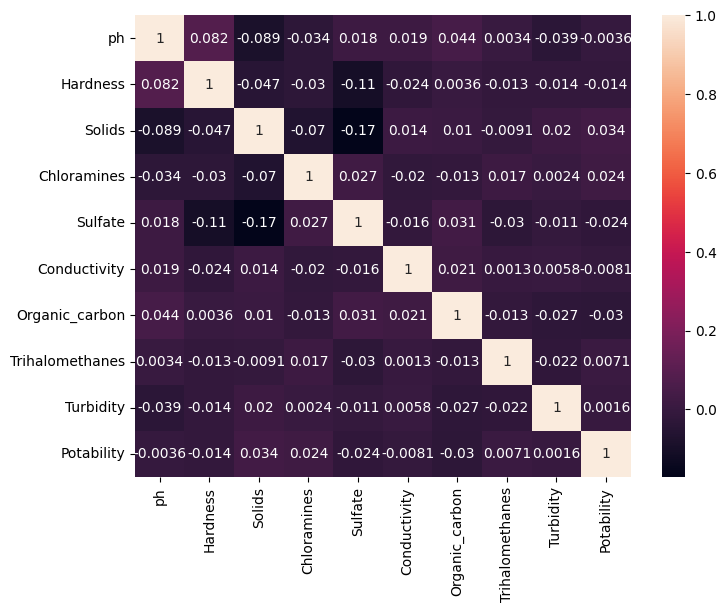

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True);

In [8]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.impute import KNNImputer
from sklearn.ensemble import IsolationForest

In [9]:
X = df.drop('Potability', axis=1)

In [10]:
y = df['Potability']

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=104, stratify=y)

In [12]:
iso_forest = IsolationForest(contamination=0.01, random_state=104, n_jobs=-1, n_estimators=100)

In [13]:
mask = iso_forest.fit_predict(X_train)

In [14]:
X_train_cleaned = X_train[mask==1]
y_train_cleaned = y_train[mask==1]

In [15]:
X_train.shape

(2620, 9)

In [16]:
X_train_cleaned.shape

(2593, 9)

In [17]:
num_transformer = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, X_train.columns.tolist())
    ],
    remainder='passthrough'
)

In [19]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier())
])

In [20]:
param_grid = {
    'model__n_neighbors': range(21, 50, 2),
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan'],
    'model__p': [1, 1.5, 2, 3]
}

In [21]:
grid_pipe = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    n_jobs=-1,
    cv=10,
    scoring='recall'
)

In [22]:
%%time
grid_pipe.fit(X_train_cleaned, y_train_cleaned)

CPU times: total: 10 s
Wall time: 57.9 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__metric': ['euclidean', 'manhattan'], 'model__n_neighbors': range(21, 50, 2), 'model__p': [1, 1.5, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computa

In [23]:
y_pred = grid_pipe.predict(X_test)
y_pred_proba = grid_pipe.predict_proba(X_test)[:, 1]
y_train_proba = grid_pipe.predict_proba(X_train)[:, 1]

In [24]:
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)

roc_auc_test = roc_auc_score(y_test, y_pred_proba)
roc_auc_train = roc_auc_score(y_train, y_train_proba)

In [25]:
best_knn = grid_pipe.best_estimator_.named_steps['model']
print(f"  Количество соседей (n_neighbors): {best_knn.n_neighbors}")
print(f"  Функция весов (weights):          {best_knn.weights}")
print(f"  Формула расстояния (metric):      {best_knn.metric}")
print(f"  Алгоритм поиска (algorithm):      {best_knn.algorithm}")
print(f"                            P:      {best_knn.p}")

  Количество соседей (n_neighbors): 21
  Функция весов (weights):          distance
  Формула расстояния (metric):      euclidean
  Алгоритм поиска (algorithm):      auto
                            P:      1


In [26]:
accuracy

0.6478658536585366

In [27]:
recall

0.26171875

In [28]:
precision

0.6146788990825688

In [29]:
roc_auc_test

0.656435546875

In [30]:
roc_auc_train

0.9999877537724504

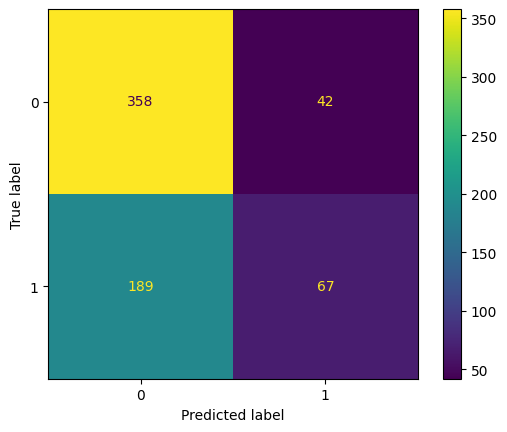

In [31]:
ConfusionMatrixDisplay.from_estimator(grid_pipe, X_test, y_test);

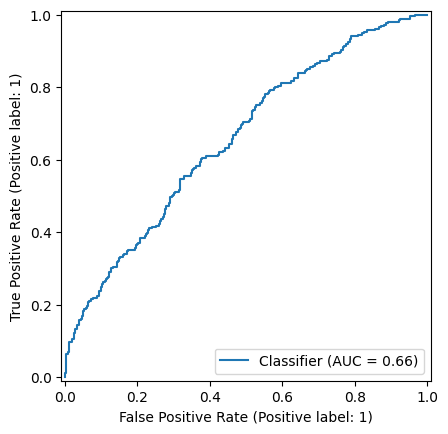

In [32]:
RocCurveDisplay.from_predictions(y_test, y_pred_proba);

In [33]:
mask = iso_forest.fit_predict(X)

In [34]:
X_cleaned = X[mask==1]
y_cleaned = y[mask==1]

In [35]:
X.shape

(3276, 9)

In [36]:
X_cleaned.shape

(3243, 9)

In [37]:
%%time
grid_pipe.fit(X_cleaned, y_cleaned)

CPU times: total: 11.7 s
Wall time: 1min 29s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__metric': ['euclidean', 'manhattan'], 'model__n_neighbors': range(21, 50, 2), 'model__p': [1, 1.5, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computa

In [38]:
y_pred_full = grid_pipe.predict_proba(X_cleaned)[:, 1]

In [39]:
best_final_knn = grid_pipe.best_estimator_.named_steps['model']
print(f"  Количество соседей (n_neighbors): {best_final_knn.n_neighbors}")
print(f"  Функция весов (weights):          {best_final_knn.weights}")
print(f"  Формула расстояния (metric):      {best_final_knn.metric}")
print(f"  Алгоритм поиска (algorithm):      {best_final_knn.algorithm}")
print(f"                            P:      {best_final_knn.p}")

  Количество соседей (n_neighbors): 21
  Функция весов (weights):          distance
  Формула расстояния (metric):      euclidean
  Алгоритм поиска (algorithm):      auto
                            P:      1


In [40]:
roc_auc_full = roc_auc_score(y_cleaned, y_pred_full)

In [41]:
roc_auc_full

1.0

In [42]:
df[df['Potability'] == 1].head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
250,9.445130,145.805402,13168.529156,9.444471,310.583374,592.659021,8.606397,77.577460,3.875165,1
251,9.024845,128.096691,19859.676476,8.016423,300.150377,451.143481,14.770863,73.778026,3.985251,1
252,NaN,169.974849,23403.637304,8.519730,NaN,475.573562,12.924107,50.861913,2.747313,1
253,6.800119,242.008082,39143.403329,9.501695,187.170714,376.456593,11.432466,73.777275,3.854940,1
254,7.174135,203.408935,20401.102461,7.681806,287.085679,315.549900,14.533510,74.405616,3.939896,1


In [43]:
water_custom_profiles = {
    'ph': [9.2, 4.5],
    'Hardness': [142.0, 310.0],
    'Solids': [13500.0, 48000.0],
    'Chloramines': [9.1, 11.5],
    'Sulfate': [315.0, 490.0],
    'Conductivity': [580.0, 620.0],
    'Organic_carbon': [9.0, 23.0],
    'Trihalomethanes': [75.0, 115.0],
    'Turbidity': [3.6, 6.8]
}

In [44]:
custom_df = pd.DataFrame(water_custom_profiles)

In [45]:
custom_df

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
0,9.2,142.0,13500.0,9.1,315.0,580.0,9.0,75.0,3.6
1,4.5,310.0,48000.0,11.5,490.0,620.0,23.0,115.0,6.8


In [46]:
custom_preds = grid_pipe.best_estimator_.predict(custom_df)
custom_probs = grid_pipe.best_estimator_.predict_proba(custom_df)

In [47]:
water_status = {
    0: "❌ ВОДА ТОКСИЧНАЯ / ХИМИЧЕСКАЯ (Пить запрещено!)",
    1: "🍏 ВОДА ПИТЬЕВАЯ / БЕЗОПАСНАЯ (Родниковый стандарт)"
}

print("="*80)
print("💧 ВЕРДИКТ МОДЕЛИ ПО КАЧЕСТВУ ВОДЫ:")
print("="*80)

for idx in range(2):
    predicted_class = custom_preds[idx]
    confidence = custom_probs[idx][predicted_class] * 100
    
    print(f"Проба №{idx+1} ({'Ожидалась Питьевая' if idx==0 else 'Ожидалась Химическая'}):")
    print(f"  -> Вердикт модели: {water_status[predicted_class]}")
    print(f"  -> Уверенность модели: {confidence:.2f}%")
    print("-" * 80)

💧 ВЕРДИКТ МОДЕЛИ ПО КАЧЕСТВУ ВОДЫ:
Проба №1 (Ожидалась Питьевая):
  -> Вердикт модели: 🍏 ВОДА ПИТЬЕВАЯ / БЕЗОПАСНАЯ (Родниковый стандарт)
  -> Уверенность модели: 64.17%
--------------------------------------------------------------------------------
Проба №2 (Ожидалась Химическая):
  -> Вердикт модели: ❌ ВОДА ТОКСИЧНАЯ / ХИМИЧЕСКАЯ (Пить запрещено!)
  -> Уверенность модели: 57.75%
--------------------------------------------------------------------------------


In [48]:
class_percents = df['Potability'].value_counts(normalize=True) * 100

baseline_string = f"0: {class_percents[0]:.1f}%, 1: {class_percents[1]:.1f}%"
print(f"{baseline_string}")

0: 61.0%, 1: 39.0%


In [49]:
import json
import os

advanced_report = {
    "project": "Water Potability Prediction",
    "model": "KNeighborsClassifier",
    "trained_date": '2026-07',
    "test_parameters": {
        "cv": grid_pipe.cv,
        "n_neighbors": best_knn.n_neighbors,
        "weights": best_knn.weights,
        "metric": best_knn.metric,
        "p": best_knn.p
    },
    "final_parameters": {
        "cv": grid_pipe.cv,
        "n_neighbors": best_final_knn.n_neighbors,
        "weights": best_final_knn.weights,
        "metric": best_final_knn.metric,
        "p": best_final_knn.p
    },
    "metrics": {
        "Accuracy Score": accuracy,
        "Precision Score": precision,
        "Recall": recall,
        "ROC AUC Score Train": roc_auc_train,
        "ROC AUC Score Test": roc_auc_test,
        "ROC AUC Score Full": roc_auc_full,
        "Class Balance": baseline_string
    }
}


filename = "model_description.json"

with open(filename, "w", encoding="utf-8") as f:
    json.dump(advanced_report, f, indent=4, ensure_ascii=False)

In [50]:
from joblib import dump, load

In [51]:
dump(grid_pipe, "model/water_potability_predict_k_neighbors_classifier_2026_v1.pkl")

['model/water_potability_predict_k_neighbors_classifier_2026_v1.pkl']

In [52]:
loaded_pipe = load("model/water_potability_predict_k_neighbors_classifier_2026_v1.pkl")

In [53]:
custom_preds = loaded_pipe.best_estimator_.predict(custom_df)
custom_probs = loaded_pipe.best_estimator_.predict_proba(custom_df)

In [54]:
water_status = {
    0: "❌ ВОДА ТОКСИЧНАЯ / ХИМИЧЕСКАЯ (Пить запрещено!)",
    1: "🍏 ВОДА ПИТЬЕВАЯ / БЕЗОПАСНАЯ (Родниковый стандарт)"
}

print("="*80)
print("💧 ВЕРДИКТ МОДЕЛИ ПО КАЧЕСТВУ ВОДЫ:")
print("="*80)

for idx in range(2):
    predicted_class = custom_preds[idx]
    confidence = custom_probs[idx][predicted_class] * 100
    
    print(f"Проба №{idx+1} ({'Ожидалась Питьевая' if idx==0 else 'Ожидалась Химическая'}):")
    print(f"  -> Вердикт модели: {water_status[predicted_class]}")
    print(f"  -> Уверенность модели: {confidence:.2f}%")
    print("-" * 80)

💧 ВЕРДИКТ МОДЕЛИ ПО КАЧЕСТВУ ВОДЫ:
Проба №1 (Ожидалась Питьевая):
  -> Вердикт модели: 🍏 ВОДА ПИТЬЕВАЯ / БЕЗОПАСНАЯ (Родниковый стандарт)
  -> Уверенность модели: 64.17%
--------------------------------------------------------------------------------
Проба №2 (Ожидалась Химическая):
  -> Вердикт модели: ❌ ВОДА ТОКСИЧНАЯ / ХИМИЧЕСКАЯ (Пить запрещено!)
  -> Уверенность модели: 57.75%
--------------------------------------------------------------------------------
